In [ ]:
%pip install BeautifulSoup4
%pip install finance-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]


In [ ]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

samsung = fdr.DataReader('005930','2016')
print(samsung)

openValues = samsung[['Open']]

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  194900   8825319  0.007235

[2660 rows x 6 columns]


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range = (0, 1))
scaled = scaler.fit_transform(openValues)

TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

def make_sample(data, window):
  train = []
  target = []
  for i in range(len(data) - window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 60) # Window Size 60으로 변경해보기

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False)
)
model.add(Dense(1))

model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(X_train, y_train, epochs = 100, batch_size = 16)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 6.7439e-04
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.9565e-05
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.1538e-05
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 6.8297e-05
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.3217e-05
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.2301e-05
Epoch 7/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.9729e-05
Epoch 8/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.7859e-05
Epoch 9/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.5215e-05
Epoch 10/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.3367e-05
Epoch 11/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.2102e-05
Epoch 12/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.9554e-05
Epoch 13/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.0843e-05
Epoch 14/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.9439e-05

In [ ]:
X_test, y_test = make_sample(test_data, 60)
pred = model.predict(X_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


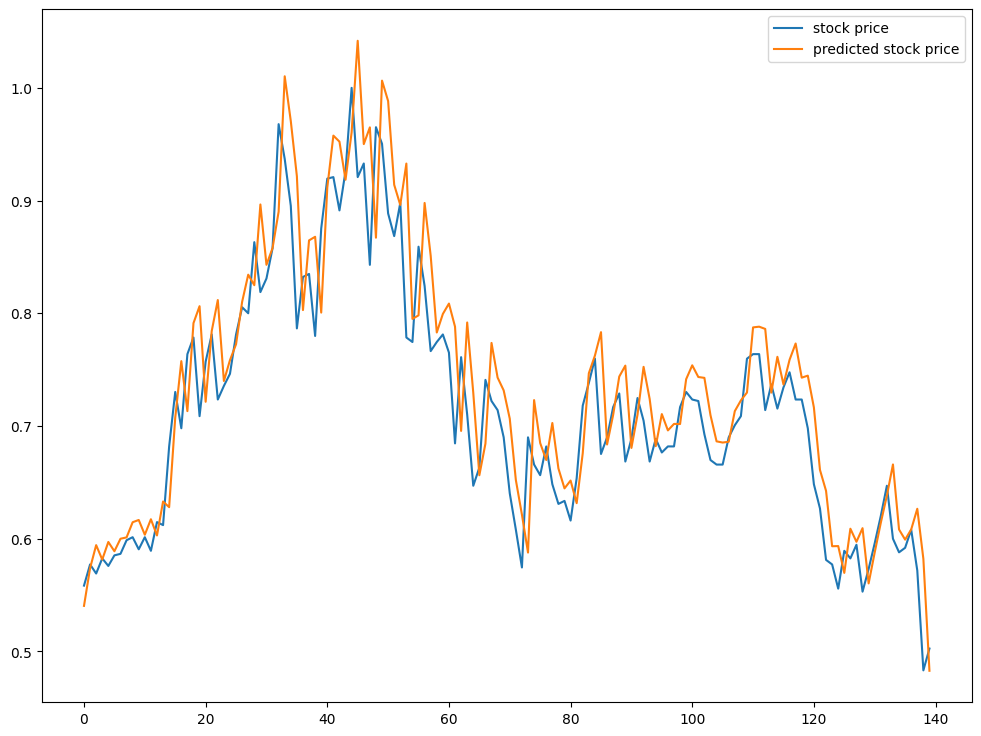

In [ ]:
plt.figure(figsize=(12, 9))
plt.plot(y_test, label="stock price")
plt.plot(pred, label="predicted stock price")
plt.legend()
plt.show()